# GNN ablations: source-data reproduction

The final cell reproduces Supplementary Fig. S14 from the corrected block-count-stratified nested training subsets under `experiments/model_selection/block_stratified_nested`. CSV values, not image pixels, are the plotting source.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import sys
STYLE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/plotting/paper_style.py').is_file()) / 'src/plotting'
sys.path.insert(0, str(STYLE_DIR))
from paper_style import COLORS, configure_paper_style, style_axis, style_distribution_axis, save_dual
configure_paper_style()
import matplotlib.pyplot as plt
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p/'experiments/model_selection/gnn/gnn').is_dir() and (p/'results/figures').is_dir())
SRC = ROOT/'experiments/model_selection/gnn/gnn'
OUT = ROOT/'results/figures/gnn'
OUT.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE = COLORS['blue'], COLORS['orange']

def read(relative, mean, sd, seeds):
    frame = pd.read_csv(SRC/relative)
    for _, row in frame.iterrows():
        values = np.asarray(json.loads(row[seeds]), dtype=float)
        assert len(values)==5 and np.isfinite(values).all()
        assert np.isclose(values.mean(), row[mean], rtol=1e-6, atol=1e-8)
        assert np.isclose(values.std(ddof=1), row[sd], rtol=1e-6, atol=1e-8)
    return frame

MEAN, SD, SEEDS = 'validation_mape_mean_percent','validation_mape_sd_percent','validation_mape_per_seed_percent'
ofat = read('hyperparameter_selection_80k/runs_100k_fixed80_20_validation_only/summary/hyperparameter_validation_summary.csv',MEAN,SD,SEEDS)
depth = read('depth_joint_grid_100k_current_ofat/summary/depth_joint_grid_validation_summary.csv',MEAN,SD,SEEDS)
abl = read('ablation_80k/runs_100k_fixed80_20_validation_only/summary/ablation_validation_summary.csv',MEAN,SD,SEEDS)
assert set(zip(depth.num_layers, depth.dec_layers))=={(e,d) for e in range(2,6) for d in range(1,4)}

def publish(fig, output_stem, *, tight=True):
    save_dual(fig, output_stem, tight=tight)
    fig.savefig(Path(output_stem).with_suffix('.pdf'), facecolor='white', **({'bbox_inches':'tight', 'pad_inches':.03} if tight else {}))
    display(Image(filename=str(Path(output_stem).with_suffix('.png')), width=1100))
    plt.close(fig)

def save(fig, name, *, tight=True):
    for ax in fig.axes:
        if ax.get_label() == '<colorbar>':
            continue
        style_axis(ax)
        if ax.get_title(): ax.title.set_fontsize(32)
        ax.margins(x=.08)
        for child in ax.child_axes: style_axis(child)
    publish(fig, OUT/name, tight=tight)



In [2]:
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, ScalarFormatter
PANEL_SPECS = (
    ("batch_size", "(a) Batch size", "Batch size", False),
    ("learning_rate", "(b) Learning rate", "Learning rate", True),
    ("hidden_dim", "(c) Hidden dimension", "Hidden dimension", False),
    ("num_layers", "(d) GNN depth", "Number of GNN layers", False),
    ("dec_layers", "(e) Decoder depth", "Number of decoder layers", False),
)

def _format_rate(value: float, _position: float) -> str:
    exponent = int(np.round(np.log10(value)))
    return rf"$10^{{{exponent}}}$"

def _panel_data(frame: pd.DataFrame, dimension: str):
    panel = frame.loc[frame["dimension"] == dimension].copy()
    panel["x_numeric"] = panel["value_label"].astype(float)
    panel = panel.sort_values("x_numeric")
    return (
        panel["x_numeric"].to_numpy(float),
        panel["validation_mape_mean_percent"].to_numpy(float),
        panel["validation_mape_sd_percent"].to_numpy(float),
    )

def _set_limits(ax, plot_x: np.ndarray, y: np.ndarray, err: np.ndarray, log_x: bool) -> None:
    low = float(np.min(y - err))
    high = float(np.max(y + err))
    span = max(high - low, 0.2)
    ax.set_ylim(max(0.0, low - 0.18 * span), high + 0.22 * span)
    if log_x:
        ax.set_xlim(float(np.min(plot_x)) / 1.65, float(np.max(plot_x)) * 1.65)
    else:
        ax.set_xlim(-0.42, len(plot_x) - 0.58)

def _add_gnn_depth_inset(
    ax, plot_x: np.ndarray, y: np.ndarray, err: np.ndarray, selected_index: int
) -> None:
    """Resolve the compressed three-to-five-layer region in panel (d)."""
    local = np.arange(len(plot_x)) >= 2
    inset = ax.inset_axes([0.47, 0.45, 0.47, 0.46])
    inset.errorbar(
        plot_x[local],
        y[local],
        yerr=err[local],
        color=COLORS["blue"],
        marker="o",
        markersize=5.5,
        markerfacecolor=COLORS["blue"],
        markeredgecolor="#FFFFFF",
        markeredgewidth=0.7,
        linewidth=2.2,
        elinewidth=1.6,
        capsize=3,
        capthick=1.4,
        zorder=2,
    )
    inset.scatter(
        [plot_x[selected_index]],
        [y[selected_index]],
        s=75,
        color=COLORS["orange"],
        edgecolors=COLORS["black"],
        linewidths=1.0,
        zorder=4,
    )
    inset.set_xlim(1.72, 4.28)
    inset.set_ylim(0.35, 1.40)
    inset.set_xticks(plot_x[local])
    inset.set_xticklabels(["3", "4", "5"])
    inset.set_yticks([0.5, 1.0])
    inset.set_title("Layers 3–5", fontsize=17, pad=4)
    style_axis(inset)
    inset.tick_params(axis="both", which="major", labelsize=14, length=6, width=1.5)
    inset.tick_params(axis="both", which="minor", length=3, width=1.0)

    # A compact dashed box identifies the magnified range without drawing long
    # connector lines across the steep one-to-two-layer trend.
    ax.plot(
        [1.72, 4.28, 4.28, 1.72, 1.72],
        [0.35, 0.35, 1.40, 1.40, 0.35],
        color=COLORS["black"],
        linestyle=(0, (3, 2)),
        linewidth=1.5,
        alpha=0.70,
        zorder=3,
    )

def _plot_panel(ax, frame: pd.DataFrame, selected: dict[str, str], spec) -> None:
    dimension, title, xlabel, log_x = spec
    x, y, err = _panel_data(frame, dimension)
    plot_x = x if log_x else np.arange(len(x), dtype=float)

    ax.errorbar(
        plot_x,
        y,
        yerr=err,
        color=COLORS["blue"],
        marker="o",
        markersize=7,
        markerfacecolor=COLORS["blue"],
        markeredgecolor="#FFFFFF",
        markeredgewidth=0.8,
        linewidth=2.8,
        elinewidth=2.0,
        capsize=4,
        capthick=1.8,
        zorder=2,
        label="5-seed mean ± SD",
    )

    selected_x = float(selected[dimension])
    selected_index = int(np.flatnonzero(np.isclose(x, selected_x))[0])
    selected_plot_x = selected_x if log_x else float(selected_index)
    ax.scatter(
        [selected_plot_x],
        [y[selected_index]],
        s=115,
        color=COLORS["orange"],
        edgecolors=COLORS["black"],
        linewidths=1.2,
        zorder=4,
        label="Selected",
    )

    if log_x:
        ax.set_xscale("log")
        ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0,), numticks=10))
        ax.xaxis.set_major_formatter(FuncFormatter(_format_rate))
        ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
        ax.xaxis.set_minor_formatter(NullFormatter())
    else:
        ax.set_xticks(plot_x)
        ax.set_xticklabels([f"{value:g}" for value in x])

    _set_limits(ax, plot_x, y, err, log_x)
    ax.set_title(title, fontsize=32, pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Validation MAPE (%)")
    style_axis(ax)
    if dimension == "num_layers":
        _add_gnn_depth_inset(ax, plot_x, y, err, selected_index)
selected=json.loads((SRC/'hyperparameter_selection_80k/runs_100k_fixed80_20_validation_only/summary/selected_by_validation_mape.json').read_text())['selected_values']
fig,axes=plt.subplots(2,3,figsize=(20.5,13.8),layout='constrained')
for ax,spec in zip(axes.flat,PANEL_SPECS): _plot_panel(ax,ofat,selected,spec)
ax=axes.flat[5]
for d,color,marker in [(1,BLUE,'o'),(2,COLORS['teal'],'s'),(3,COLORS['purple'],'^')]:
    f=depth[depth.dec_layers==d].sort_values('num_layers')
    ax.errorbar(f.num_layers,f[MEAN],yerr=f[SD],fmt=marker+{1:'-',2:'--',3:':'}[d],color=color,capsize=3,label=f'D{d}')
ax.set(yscale='log',xticks=[2,3,4,5],xlabel='Encoder depth',ylabel='Validation MAPE (%)',title='(f) Depth interaction')
ax.legend(title='Decoder depth',fontsize=24)
best=depth.loc[depth[MEAN].idxmin()]
ax.scatter(best.num_layers,best[MEAN],marker='*',s=150,color=ORANGE,edgecolor='black',zorder=5)
style_axis(ax)
ax.title.set_fontsize(32)
publish(fig,OUT/'gnn_hyperparameter_screening')

frame = ofat
selected = json.loads((SRC/'hyperparameter_selection_80k/runs_100k_fixed80_20_validation_only/summary/selected_by_validation_mape.json').read_text())['selected_values']

# Keep all panels at the same size: three across the top and two centered
# beneath them. A six-column grid gives each axis an equal two-column span.
fig = plt.figure(figsize=(16.0, 10.76), facecolor="white")
grid = fig.add_gridspec(2, 6, wspace=0.85, hspace=0.78)
axes = (
    fig.add_subplot(grid[0, 0:2]),
    fig.add_subplot(grid[0, 2:4]),
    fig.add_subplot(grid[0, 4:6]),
    fig.add_subplot(grid[1, 1:3]),
    fig.add_subplot(grid[1, 3:5]),
)

for ax, spec in zip(axes, PANEL_SPECS):
    _plot_panel(ax, frame, selected, spec)

handles, labels = axes[0].get_legend_handles_labels()
legend_items = dict(zip(labels, handles))
axes[0].legend(
    [legend_items["5-seed mean ± SD"], legend_items["Selected"]],
    ["5-seed mean ± SD", "Selected"],
    loc="upper center",
    bbox_to_anchor=(0.61, 0.99),
    ncol=1,
    frameon=False,
    handlelength=1.4,
    handletextpad=0.45,
)
fig.subplots_adjust(left=0.075, right=0.985, top=0.94, bottom=0.095)
plt.close(fig)

from matplotlib.ticker import FixedLocator
SERIES_STYLE = {
    1: {"color": COLORS["blue"], "marker": "o", "linestyle": "-"},
    2: {"color": COLORS["teal"], "marker": "s", "linestyle": "--"},
    3: {"color": COLORS["purple"], "marker": "^", "linestyle": ":"},
}

def _load_complete_grid(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    expected = {(encoder, decoder) for encoder in range(2, 6) for decoder in range(1, 4)}
    observed = set(zip(frame["num_layers"].astype(int), frame["dec_layers"].astype(int)))
    if observed != expected:
        missing = sorted(expected.difference(observed))
        extra = sorted(observed.difference(expected))
        raise RuntimeError(f"Incomplete E2–E5 × D1–D3 grid; missing={missing}, extra={extra}")
    if not (frame["n_seeds"].astype(int) == 5).all():
        raise RuntimeError("Every depth cell must contain five seeds")
    return frame

def _format_log_tick(value: float, _position: float) -> str:
    return f"{value:g}"
frame = depth
fig, ax = plt.subplots(figsize=(10.5, 8.5), facecolor="white")

for decoder in (1, 2, 3):
    series = frame.loc[frame["dec_layers"] == decoder].sort_values("num_layers")
    style = SERIES_STYLE[decoder]
    ax.errorbar(
        series["num_layers"],
        series["validation_mape_mean_percent"],
        yerr=series["validation_mape_sd_percent"],
        color=style["color"],
        linestyle=style["linestyle"],
        marker=style["marker"],
        markersize=9,
        markerfacecolor=style["color"],
        markeredgecolor="#FFFFFF",
        markeredgewidth=0.9,
        linewidth=2.8,
        elinewidth=2.0,
        capsize=5,
        capthick=1.8,
        label=f"D{decoder}",
        zorder=2,
    )

e4d1 = frame.loc[(frame["num_layers"] == 4) & (frame["dec_layers"] == 1)].iloc[0]
e5d1 = frame.loc[(frame["num_layers"] == 5) & (frame["dec_layers"] == 1)].iloc[0]
ax.scatter(
    [4],
    [e4d1.validation_mape_mean_percent],
    s=190,
    facecolors="none",
    edgecolors=COLORS["black"],
    linewidths=2.2,
    zorder=4,
)
ax.scatter(
    [5],
    [e5d1.validation_mape_mean_percent],
    s=310,
    marker="*",
    color=COLORS["orange"],
    edgecolors=COLORS["black"],
    linewidths=1.2,
    zorder=5,
)

ax.annotate(
    "OFAT E4D1",
    xy=(4, e4d1.validation_mape_mean_percent),
    xytext=(3.38, 0.53),
    fontsize=21,
    ha="center",
    va="center",
    arrowprops={
        "arrowstyle": "->",
        "color": COLORS["black"],
        "linewidth": 1.8,
        "shrinkA": 3,
        "shrinkB": 7,
    },
    zorder=6,
)
ax.annotate(
    "Selected E5D1",
    xy=(5, e5d1.validation_mape_mean_percent),
    xytext=(4.48, 0.43),
    fontsize=21,
    color=COLORS["orange"],
    ha="center",
    va="center",
    arrowprops={
        "arrowstyle": "->",
        "color": COLORS["orange"],
        "linewidth": 1.8,
        "shrinkA": 3,
        "shrinkB": 9,
    },
    zorder=6,
)

ax.set_yscale("log")
ax.set_xlim(1.75, 5.25)
ax.set_ylim(0.36, 16.5)
ax.set_xticks([2, 3, 4, 5])
ax.set_xticklabels(["E2", "E3", "E4", "E5"])
ax.set_xlabel("Number of GNN/encoder layers")
ax.set_ylabel("Validation MAPE (%)")
ax.set_title("Encoder–decoder depth interaction", fontsize=32, pad=14)
ax.text(
    0.035,
    0.045,
    "mean ± SD, $n=5$ seeds",
    transform=ax.transAxes,
    fontsize=20,
    ha="left",
    va="bottom",
    color="0.25",
)
ax.legend(
    title="Decoder depth",
    loc="upper right",
    ncol=1,
    frameon=False,
    handlelength=2.1,
    borderaxespad=0.7,
)

style_axis(ax)
ax.yaxis.set_major_locator(FixedLocator([0.5, 1, 2, 5, 10]))
ax.yaxis.set_major_formatter(FuncFormatter(_format_log_tick))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.yaxis.set_minor_formatter(NullFormatter())
fig.subplots_adjust(left=0.16, right=0.95, bottom=0.15, top=0.90)
plt.close(fig)


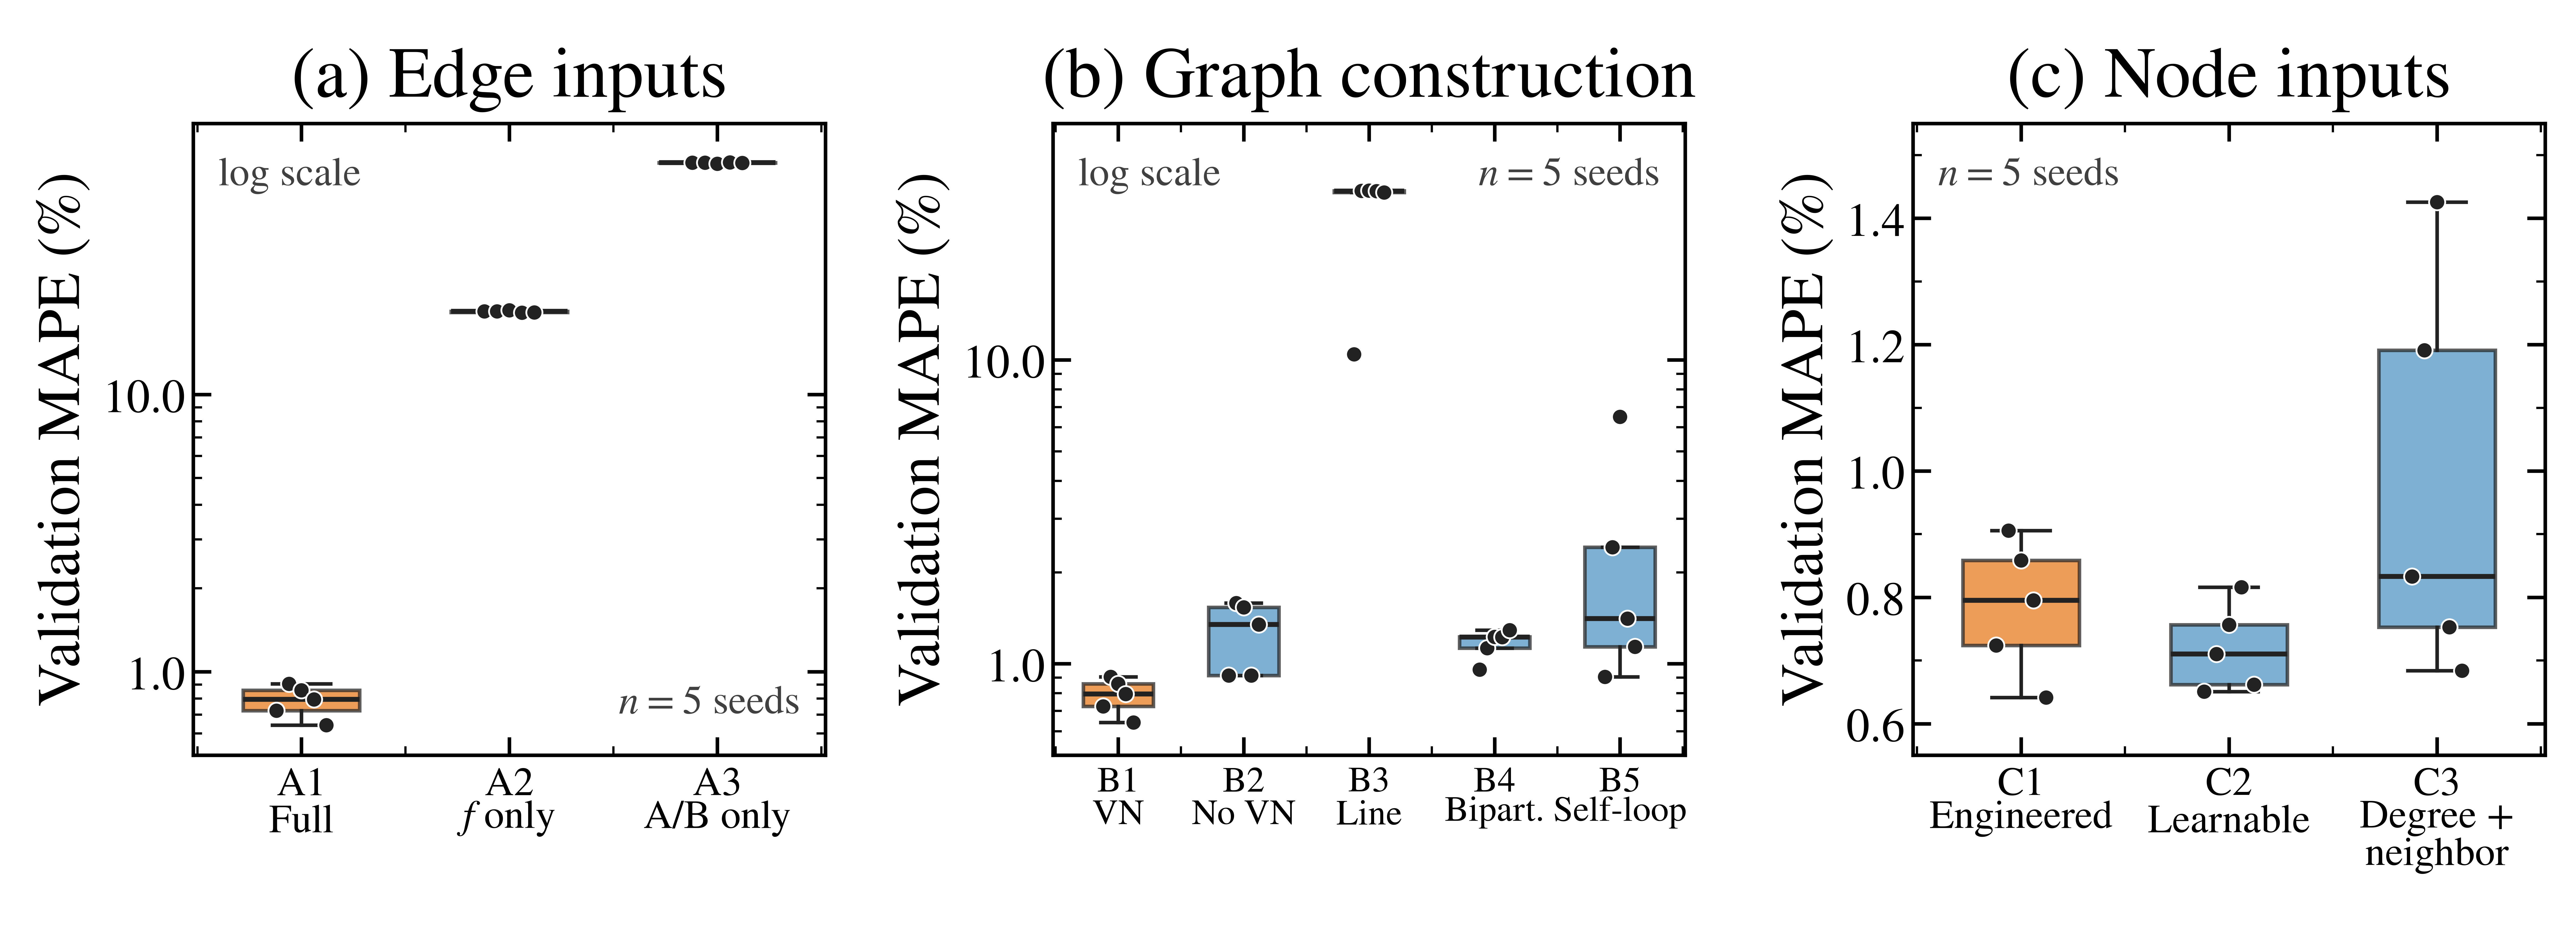

In [3]:
PANELS = (
    {
        "title": "(a) Edge inputs",
        "keys": ("S01", "A2", "A3"),
        "labels": ("A1\nFull", "A2\n$f$ only", "A3\nA/B only"),
        "log_y": True,
        "ylim": (0.50, 95.0),
        "n_position": (0.96, 0.05, "right", "bottom"),
    },
    {
        "title": "(b) Graph construction",
        "keys": ("S01", "B2", "B3", "B4", "B5"),
        "labels": (
            "B1\nVN",
            "B2\nNo VN",
            "B3\nLine",
            "B4\nBipart.",
            "B5\nSelf-loop",
        ),
        "log_y": True,
        "ylim": (0.50, 60.0),
        "n_position": (0.96, 0.95, "right", "top"),
    },
    {
        "title": "(c) Node inputs",
        "keys": ("S01", "C2", "C3"),
        "labels": ("C1\nEngineered", "C2\nLearnable", "C3\nDegree +\nneighbor"),
        "log_y": False,
        "ylim": (0.55, 1.55),
        "n_position": (0.04, 0.95, "left", "top"),
    },
)

def _load_scores(path: Path) -> dict[str, np.ndarray]:
    frame = pd.read_csv(path)
    scores: dict[str, np.ndarray] = {}
    for row in frame.itertuples(index=False):
        values = np.asarray(json.loads(row.validation_mape_per_seed_percent), dtype=float)
        if values.size != 5 or not np.all(np.isfinite(values)):
            raise RuntimeError(f"Expected five finite seed scores for {row.condition_key}")
        aliases = str(row.aliases).split(";")
        canonical = "S01" if "S01" in str(row.condition_key) else aliases[0]
        scores[canonical] = values
    required = {key for panel in PANELS for key in panel["keys"]}
    missing = required.difference(scores)
    if missing:
        raise RuntimeError(f"Missing ablation conditions: {sorted(missing)}")
    return scores

def _plot_panel(ax, scores: dict[str, np.ndarray], panel: dict) -> None:
    values = [scores[key] for key in panel["keys"]]
    positions = np.arange(1, len(values) + 1, dtype=float)
    box = ax.boxplot(
        values,
        positions=positions,
        widths=0.56,
        patch_artist=True,
        showfliers=False,
        whis=1.5,
        boxprops={"edgecolor": COLORS["black"], "linewidth": 1.6},
        medianprops={"color": COLORS["black"], "linewidth": 2.2},
        whiskerprops={"color": COLORS["black"], "linewidth": 1.6},
        capprops={"color": COLORS["black"], "linewidth": 1.6},
    )
    for index, patch in enumerate(box["boxes"]):
        patch.set_facecolor(COLORS["orange"] if index == 0 else COLORS["blue"])
        patch.set_alpha(0.72)

    # Deterministic offsets expose every seed without implying another variable.
    offsets = np.linspace(-0.12, 0.12, 5)
    for position, seed_scores in zip(positions, values):
        ax.scatter(
            position + offsets,
            seed_scores,
            s=52,
            color=COLORS["black"],
            edgecolors="#FFFFFF",
            linewidths=0.8,
            zorder=4,
        )

    style_distribution_axis(ax)
    if panel["log_y"]:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0,), numticks=5))
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.text(
            0.04,
            0.95,
            "log scale",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=18,
            color="0.25",
        )

    ax.set_xlim(0.48, len(values) + 0.52)
    ax.set_ylim(*panel["ylim"])
    ax.set_xticks(positions)
    x_label_size = 16 if len(values) == 5 else 18
    ax.set_xticklabels(panel["labels"], fontsize=x_label_size, linespacing=0.92)
    ax.set_title(panel["title"], fontsize=32, pad=12)
    ax.set_ylabel("Validation MAPE (%)", fontsize=27)
    n_x, n_y, n_ha, n_va = panel["n_position"]
    ax.text(
        n_x,
        n_y,
        "$n=5$ seeds",
        transform=ax.transAxes,
        ha=n_ha,
        va=n_va,
        fontsize=18,
        color="0.25",
    )
    ax.tick_params(axis="y", which="major", labelsize=21)
scores=_load_scores(SRC/'ablation_80k/runs_100k_fixed80_20_validation_only/summary/ablation_validation_summary.csv')
fig,axes=plt.subplots(1,3,figsize=(16,5.9),facecolor='white')
for ax,panel in zip(axes,PANELS): _plot_panel(ax,scores,panel)
fig.subplots_adjust(left=.075,right=.988,bottom=.205,top=.87,wspace=.36)
publish(fig,OUT/'gnn_representation_ablation',tight=False)


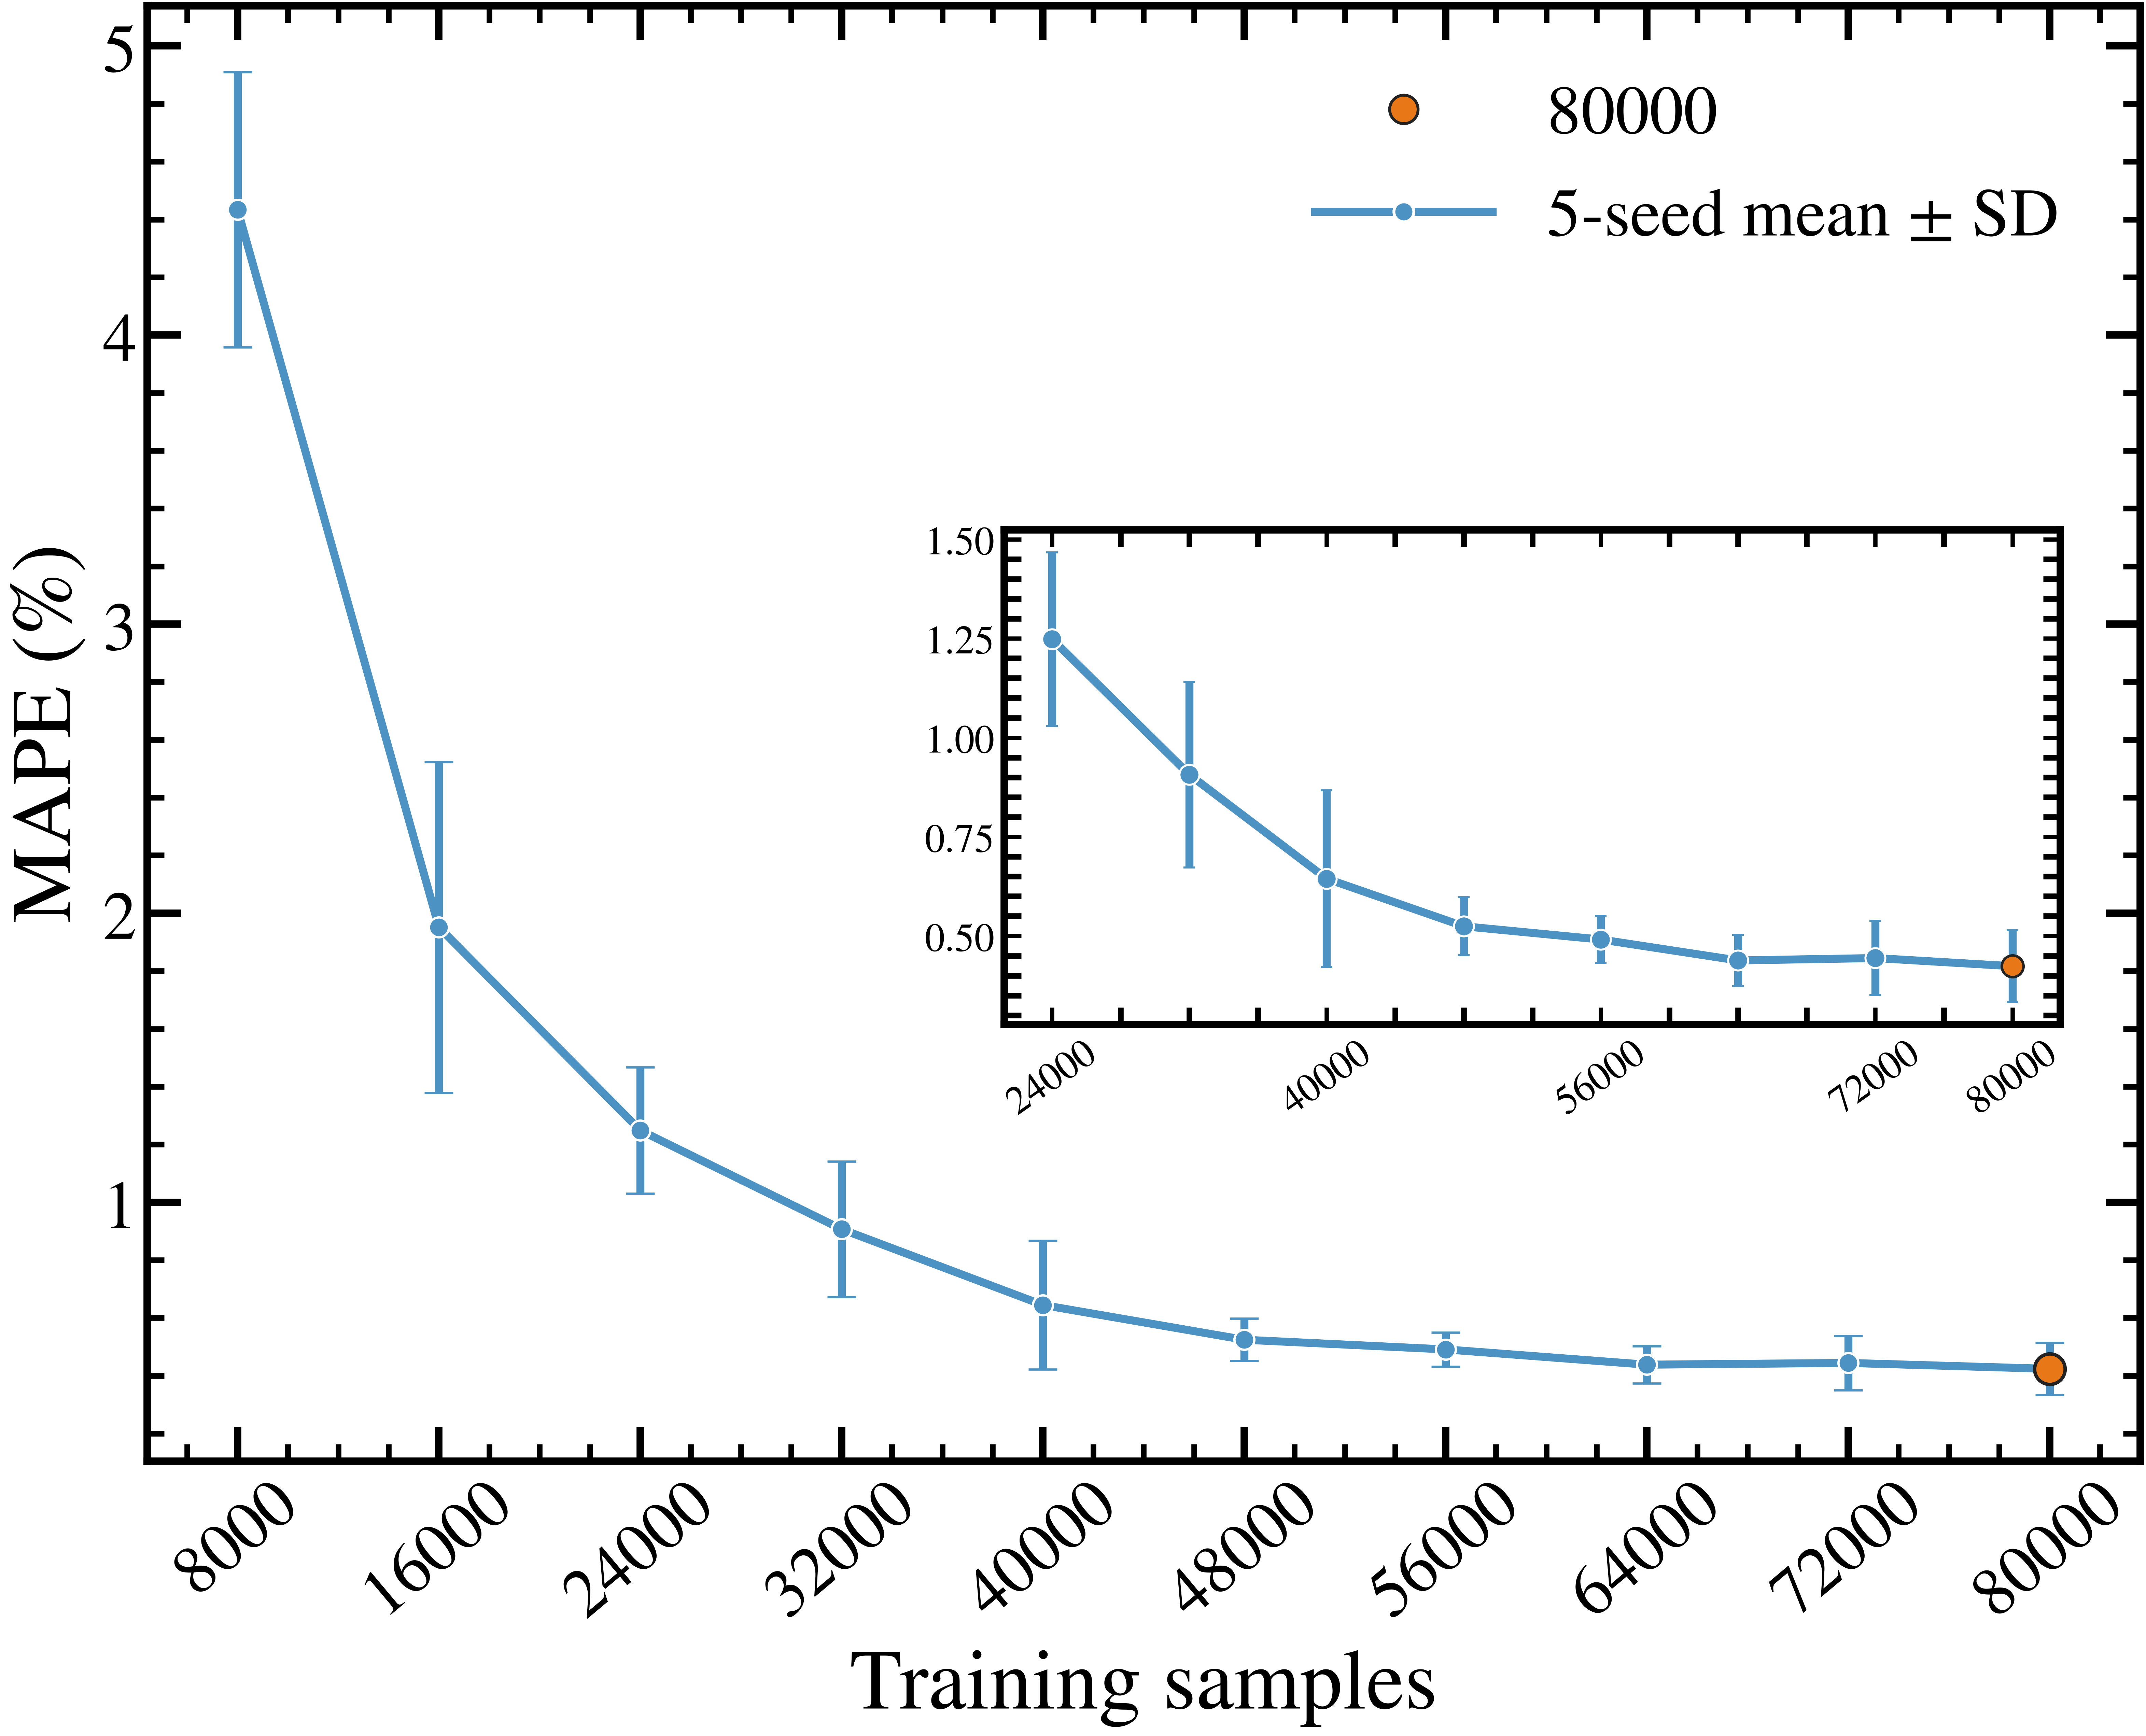

C2 block-stratified endpoints: 4.433620929718018 0.42376730442047117


In [4]:
from matplotlib.lines import Line2D
corrected=ROOT/'experiments/model_selection/block_stratified_nested/results/gnn'
f=pd.read_csv(corrected/'summary/c2_block_stratified_nested_validation_summary.csv').sort_values('train_size')
final_dir=ROOT/'results/source_data/final_evaluation/gnn/gnn/finalmodel/seed43_independent_2k_inference'
final_values=pd.read_csv(final_dir/'per_seed_metrics.csv')['mape_percent'].to_numpy(float)
assert list(f.train_size)==list(range(8000,80001,8000)) and (f.n_seeds==5).all()
assert final_values.size==5 and np.isfinite(final_values).all()
mean='development_validation_mape_mean_percent'; sd='development_validation_mape_sd_percent'
f.loc[f.train_size==80000,mean]=final_values.mean()
f.loc[f.train_size==80000,sd]=final_values.std(ddof=1)
fig,ax=plt.subplots(figsize=(10.5,8.5),layout='constrained')
x=f.train_size
ax.errorbar(x,f[mean],yerr=f[sd],fmt='o-',color=BLUE,capsize=5,markeredgecolor='white',markeredgewidth=.8,label='5-seed mean ± SD')
ax.scatter([80000],[f.iloc[-1][mean]],s=115,color=ORANGE,edgecolors=COLORS['black'],linewidths=1.2,zorder=4,label='80000')
legend_handles = [
    Line2D([0],[0],marker='o',linestyle='none',markersize=10,markerfacecolor=ORANGE,markeredgecolor=COLORS['black'],label='80000'),
    Line2D([0],[0],color=BLUE,linewidth=2.8,marker='o',markersize=7,markerfacecolor=BLUE,markeredgecolor='white',label='5-seed mean ± SD'),
]
ax.legend(handles=legend_handles,loc='upper right',bbox_to_anchor=(.99,.99),handlelength=2.6)
ax.set(xlabel='Training samples',ylabel='MAPE (%)',xticks=x,xticklabels=[f'{int(value)}' for value in f.train_size])
ax.tick_params(axis='x',labelrotation=40)
inset=ax.inset_axes([.43,.30,.53,.34]); z=f[f.train_size>=24000]
inset.errorbar(z.train_size,z[mean],yerr=z[sd],fmt='o-',color=BLUE,capsize=2,markeredgecolor='white',markeredgewidth=.7)
inset.scatter([80000],[z.iloc[-1][mean]],s=58,color=ORANGE,edgecolors=COLORS['black'],linewidths=.9,zorder=4)
inset.set_xticks([24000,40000,56000,72000,80000],['24000','40000','56000','72000','80000'])
inset.tick_params(labelsize=12)
inset.tick_params(axis='x',labelrotation=35)
style_axis(ax)
for child in ax.child_axes:
    style_axis(child); child.tick_params(labelsize=14,length=6,width=1.5)
publish(fig,OUT/'gnn_training_size')
print('C2 block-stratified endpoints:',f.iloc[0][mean],f.iloc[-1][mean])
